# Credit Risk Prediction

## Project Overview

This project aims to build a machine learning system that predicts the probability of loan default.

The project covers the complete machine learning workflow:

1. Data exploration
2. Data preprocessing
3. Feature engineering
4. Model training
5. Model evaluation
6. Model interpretation
7. API deployment

The target variable is `loan_status`, where:
- `0` represents non-default
- `1` represents default

# 1. Dataset

In this section, we load the credit risk dataset and examine its structure, features and target variable.

The dataset contains information about borrowers, their income, employment, loan characteristics and credit history.

The target variable is `loan_status`, which indicates whether the borrower defaulted on the loan.

In [182]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from narwhals.stable.v1.selectors import categorical

In [183]:
df = pd.read_csv("../data/credit_risk_dataset.csv")

## 1.1 Initial Data Exploration

We first inspect the dataset to understand its dimensions, structure, data types and target distribution.

In [184]:
df.head() # Display the first 5 rows of the dataset

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [185]:
df.shape # Number of rows and columns

(32581, 12)

In [186]:
df.info() # Dataset structure, data types and non-null values

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [187]:
df.isnull().sum() # Number of missing values in each column

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [188]:
df["loan_status"].value_counts() # Number of samples in each target class

loan_status
0    25473
1     7108
Name: count, dtype: int64

## 1.2 Descriptive Statistics

In this section, we examine the statistical characteristics of numerical features, including their mean, standard deviation, minimum and maximum values.

This helps identify unusual values, potential outliers and differences in feature distributions.

In [189]:
df.describe()  # Generate descriptive statistics for numerical features

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


# 2. Data Quality Analysis

Before training machine learning models, we need to identify and address data quality issues such as missing values, duplicate records and implausible values.

In [190]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [191]:
df.duplicated().sum() # Check for dublicate rows

np.int64(165)

# 3. Exploratory Data Analysis

In this section, we analyze relationships between the features and the target variable.

The goal is to understand which characteristics may be associated with loan default and identify important patterns in the dataset.

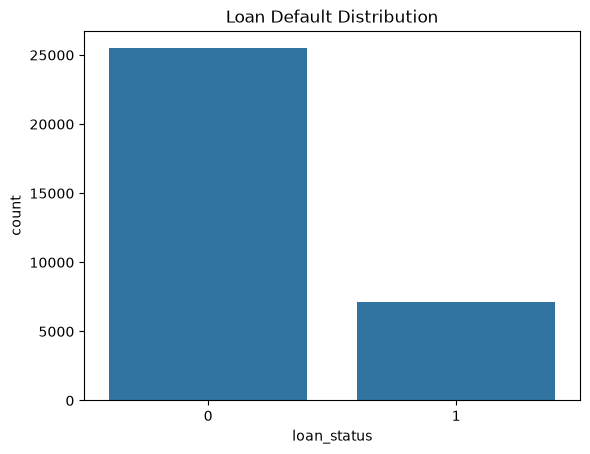

In [192]:
sns.countplot(data=df, x="loan_status")
plt.title("Loan Default Distribution")
plt.show()

# 4. Data Preprocessing

In this section, the cleaned dataset is transformed into a format suitable for machine learning models.

The preprocessing process includes:

- Separating features and target
- Identifying numerical and categorical features
- Encoding categorical variables
- Splitting the data into training and testing sets

In [193]:
x = df.drop("loan_status", axis=1) # Input features
y = df["loan_status"] # Target variable
x.shape, y.shape # Chack dimensions of features and target

((32581, 11), (32581,))

## 4.1 Feature Type Identification

Machine learning models require numerical input, so we first identify numerical and categorical features.

Numerical features contain quantitative values, while categorical features contain labels or categories.

In [194]:
x.select_dtypes(include="number").columns # Select columns containing numerical values

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='str')

In [195]:
x.select_dtypes(include="object").columns # Select columns containing categorical values

/var/folders/v2/mprvgzcd1k14z93y5ns9pwfr0000gn/T/ipykernel_45321/805787076.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  x.select_dtypes(include="object").columns # Select columns containing categorical values


Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='str')

In [196]:
for col in x.select_dtypes(include="str").columns:
    print(col, x[col].unique()) # Display unique categories for each categorical feature

person_home_ownership <StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
loan_intent <StringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str
loan_grade <StringArray>
['D', 'B', 'C', 'A', 'E', 'F', 'G']
Length: 7, dtype: str
cb_person_default_on_file <StringArray>
['Y', 'N']
Length: 2, dtype: str


## 4.2 Categorical Encoding

Machine learning models require numerical input, so categorical features must be converted into numerical representations before model training.

Categorical variables can be divided into two types:

- **Nominal features:** Categories have no inherent order. Examples in this dataset include `person_home_ownership`, `loan_intent`, and `cb_person_default_on_file`. These features will be encoded using One-Hot Encoding.

- **Ordinal features:** Categories have a meaningful order. `loan_grade` is an ordinal feature because the grades follow a risk-related order from A to G. This ordering should be preserved during encoding.

Using the appropriate encoding method prevents the model from interpreting unrelated categories as having an artificial numerical relationship.

### Identifying Feature Types

Before applying encoding, we separate numerical and categorical features based on their data types.

In [197]:
numeric_features = x.select_dtypes(include="number").columns # Identify numerical features
categorical_features = x.select_dtypes(include="str").columns # Identify categorical features

In [198]:
numeric_features  # Display numerical feature names

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='str')

In [199]:
categorical_features  # Display categorical feature names


Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='str')

### 4.2.1 Encoding Strategy

Different encoding methods are used depending on the nature of each categorical feature.

`loan_grade` is treated as an ordinal feature because its categories have a meaningful order from A to G. Therefore, Ordinal Encoding will be used to preserve this relationship.

The remaining categorical features are nominal, meaning that their categories do not have an inherent order. These features will be encoded using One-Hot Encoding.

This approach allows the model to use categorical information without introducing artificial relationships between unrelated categories.

In [200]:
ordinal_features = ["loan_grade"] # Features with an inherent order

onehot_features = [ # Features without an inherent order
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

### 4.2.2 Define Encoders

The appropriate encoders are defined for each type of categorical feature.

`OrdinalEncoder` is used for `loan_grade` to preserve its ordinal relationship, while `OneHotEncoder` is used for nominal categorical features.

In [201]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

ordinal_encoder = OrdinalEncoder()  # Encode ordered categories numerically

onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)  # Encode nominal categories using one-hot encoding

### 4.2.3 Build Preprocessing Pipeline

A preprocessing pipeline is created to apply the appropriate encoding method to each categorical feature.

`ColumnTransformer` allows different transformations to be applied to different groups of columns while keeping the preprocessing steps organized in a single pipeline.

In [202]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", ordinal_encoder)
])

onehot_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", onehot_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("ordinal", ordinal_pipeline, ordinal_features),
        ("onehot", onehot_pipeline, onehot_features)
    ]
)

### 4.2.4 Apply Encoding

The preprocessing transformer is now fitted to the input features and used to transform the categorical variables into numerical representations.

The resulting dataset contains the encoded categorical features together with the original numerical features.

In [203]:
x_encoded = preprocessor.fit_transform(x)  # Fit the encoders and transform the input features

x_encoded.shape  # Check the dimensions of the encoded dataset

(32581, 20)

## 4.3 Train/Test Split

The dataset is divided into training and testing subsets.

The training set is used to learn the patterns in the data, while the test set is reserved for evaluating the model on unseen data.

An 80/20 split is used. Stratification is applied to preserve the class distribution of the target variable in both subsets.

In [204]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((26064, 20), (6517, 20), (26064,), (6517,))

# 5. Model Training

We train multiple machine learning models and compare their performance.

The initial models will include:

- Logistic Regression
- Random Forest
- XGBoost

## 5.1 Logistic Regression

Logistic Regression is used as the first baseline classification model.

The model estimates the probability of a loan default based on the available input features. A probability threshold is then used to assign the prediction to one of the two target classes: non-default (0) or default (1).

Logistic Regression provides a simple and interpretable baseline that can later be compared with more complex models such as Random Forest and XGBoost.

In [205]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    solver="liblinear",
    max_iter=1000,
    random_state=42
)  # Initialize the Logistic Regression model

In [206]:
logistic_model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

### Making Predictions

After training the Logistic Regression model, predictions are generated using the unseen test dataset.

The model outputs a binary prediction for each test sample:
0 represents non-default and 1 represents default.

In [207]:
y_pred = logistic_model.predict(x_test)  # Generate predictions for the test set

y_pred[:10]  # Display the first 10 predictions

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

### 5.2 Random Forest

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to make predictions.

Instead of relying on a single tree, the model aggregates the predictions of multiple trees. This can improve robustness and reduce the risk of overfitting compared with using a single Decision Tree.

In [208]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)  # Initialize the Random Forest model

In [209]:
random_forest_model.fit(x_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

### Making Predictions

The trained Random Forest model is used to generate predictions on the unseen test dataset.

These predictions will later be compared with the actual target values to evaluate the model's performance.

In [210]:
y_pred_rf = random_forest_model.predict(x_test)  # Generate predictions for the test set

y_pred_rf[:10]  # Display the first 10 predictions

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

### 5.3 XGBoost

XGBoost is a gradient boosting algorithm based on decision trees.

The model builds trees sequentially, with each new tree focusing on reducing the errors made by the previous trees. This makes XGBoost a powerful model for structured and tabular datasets.

The XGBoost model will be trained using the same training data used for the previous models.

In [211]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42
)  # Initialize the XGBoost model

In [212]:
xgb_model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [213]:
y_pred_xgb = xgb_model.predict(x_test)  # Generate predictions for the test set
y_pred_xgb[:10]  # Display the first 10 predictions

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

# 6. Model Evaluation

After training the models, their performance must be evaluated on the unseen test dataset.

The evaluation compares the predicted values with the actual target values in `y_test`.

The following classification metrics will be used:

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** Among the samples predicted as default, the proportion that are actually default.
- **Recall:** Among the actual default cases, the proportion correctly identified by the model.
- **F1-score:** The harmonic mean of precision and recall.

These metrics provide a more complete view of model performance than accuracy alone.

In [214]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Logistic Regression
Accuracy: 0.8566825226331134
Precision: 0.7494887525562373
Recall: 0.5154711673699015
F1-score: 0.6108333333333333


In [215]:
print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))

Random Forest
Accuracy: 0.935246278962713
Precision: 0.9789272030651341
Recall: 0.7187060478199718
F1-score: 0.8288726682887266


In [216]:
print("XGBoost")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-score:", f1_score(y_test, y_pred_xgb))

XGBoost
Accuracy: 0.9366272824919442
Precision: 0.9827751196172249
Recall: 0.7222222222222222
F1-score: 0.8325901905147953


### Evaluation Results

The three models show clear differences in classification performance.

Logistic Regression provides the weakest overall performance. Although its accuracy is approximately 80.3%, its recall for the default class is only 15.8%. This indicates that the model fails to identify a large proportion of actual default cases.

Random Forest significantly improves the results, achieving approximately 93.5% accuracy and an F1-score of 82.8%. Its recall of 71.8% indicates that it identifies a substantially larger proportion of default cases.

XGBoost achieves the strongest overall performance, with approximately 93.7% accuracy, 98.3% precision, 72.2% recall, and an F1-score of 83.6%.

Based on these metrics, XGBoost is selected as the best-performing model among the three evaluated approaches.

### Confusion Matrix

A confusion matrix shows how the model's predictions are distributed across the actual classes.

For this credit risk problem:

- **True Negative (TN):** A non-default customer correctly predicted as non-default.
- **False Positive (FP):** A non-default customer incorrectly predicted as default.
- **False Negative (FN):** A default customer incorrectly predicted as non-default.
- **True Positive (TP):** A default customer correctly predicted as default.

False Negatives are particularly important in credit risk because they represent customers who are predicted as low risk but actually default.

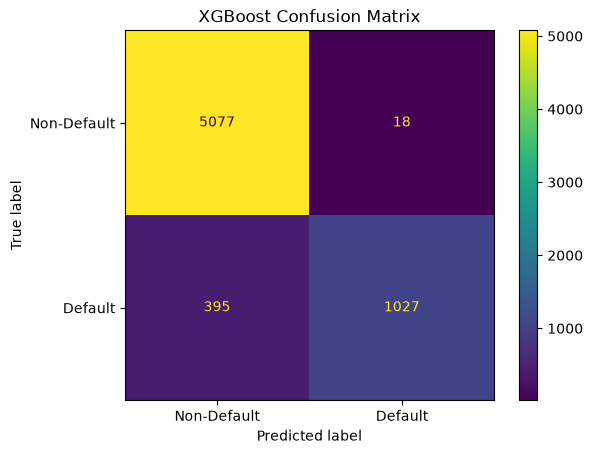

In [217]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_xgb)  # Calculate the confusion matrix for XGBoost

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

### Confusion Matrix Comparison

Confusion matrices can also be used to compare the classification errors of the three models.

The matrices show how many samples were correctly classified and how many were misclassified as each class.

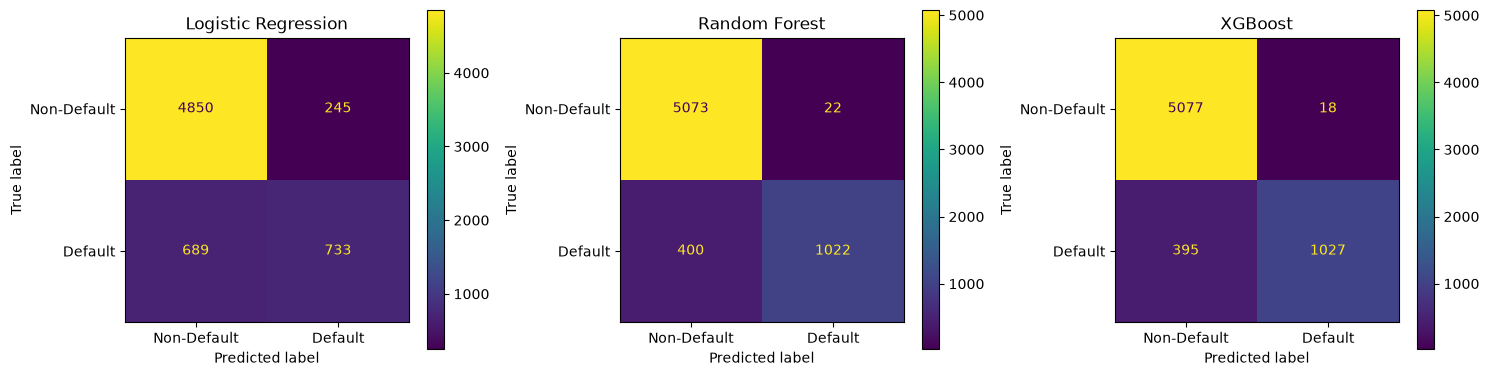

In [218]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["Non-Default", "Default"]
).plot(ax=axes[0])

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf),
    display_labels=["Non-Default", "Default"]
).plot(ax=axes[1])

axes[1].set_title("Random Forest")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_xgb),
    display_labels=["Non-Default", "Default"]
).plot(ax=axes[2])

axes[2].set_title("XGBoost")

plt.tight_layout()
plt.show()

### ROC-AUC

ROC-AUC measures how well a classification model can distinguish between the two target classes.

The ROC curve evaluates the model across different classification thresholds by comparing the True Positive Rate and False Positive Rate.

The AUC value ranges from 0 to 1. A higher AUC indicates better ability to distinguish between non-default and default cases.

In [219]:
from sklearn.metrics import roc_auc_score

logistic_auc = roc_auc_score(
    y_test,
    logistic_model.predict_proba(x_test)[:, 1]
)

rf_auc = roc_auc_score(
    y_test,
    random_forest_model.predict_proba(x_test)[:, 1]
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_model.predict_proba(x_test)[:, 1]
)

print("Logistic Regression AUC:", logistic_auc)
print("Random Forest AUC:", rf_auc)
print("XGBoost AUC:", xgb_auc)

Logistic Regression AUC: 0.8658998024869257
Random Forest AUC: 0.9303597332814362
XGBoost AUC: 0.9492712305851273


# 7. Model Interpretation

Model performance metrics show how well the model predicts the target variable, but they do not explain why individual predictions are made.

Model interpretation helps identify which features contribute most to the model's predictions.

SHAP (SHapley Additive exPlanations) is used to analyze the contribution of individual features to the XGBoost model's predictions.

This allows us to understand which characteristics have the strongest influence on credit default predictions.

In [220]:
import shap

explainer = shap.TreeExplainer(xgb_model)  # Create a SHAP explainer for XGBoost
shap_values = explainer(x_test)  # Calculate SHAP values for the test data

In [221]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['numeric__person_age' 'numeric__person_income'
 'numeric__person_emp_length' 'numeric__loan_amnt'
 'numeric__loan_int_rate' 'numeric__loan_percent_income'
 'numeric__cb_person_cred_hist_length' 'ordinal__loan_grade'
 'onehot__person_home_ownership_MORTGAGE'
 'onehot__person_home_ownership_OTHER' 'onehot__person_home_ownership_OWN'
 'onehot__person_home_ownership_RENT'
 'onehot__loan_intent_DEBTCONSOLIDATION' 'onehot__loan_intent_EDUCATION'
 'onehot__loan_intent_HOMEIMPROVEMENT' 'onehot__loan_intent_MEDICAL'
 'onehot__loan_intent_PERSONAL' 'onehot__loan_intent_VENTURE'
 'onehot__cb_person_default_on_file_N'
 'onehot__cb_person_default_on_file_Y']


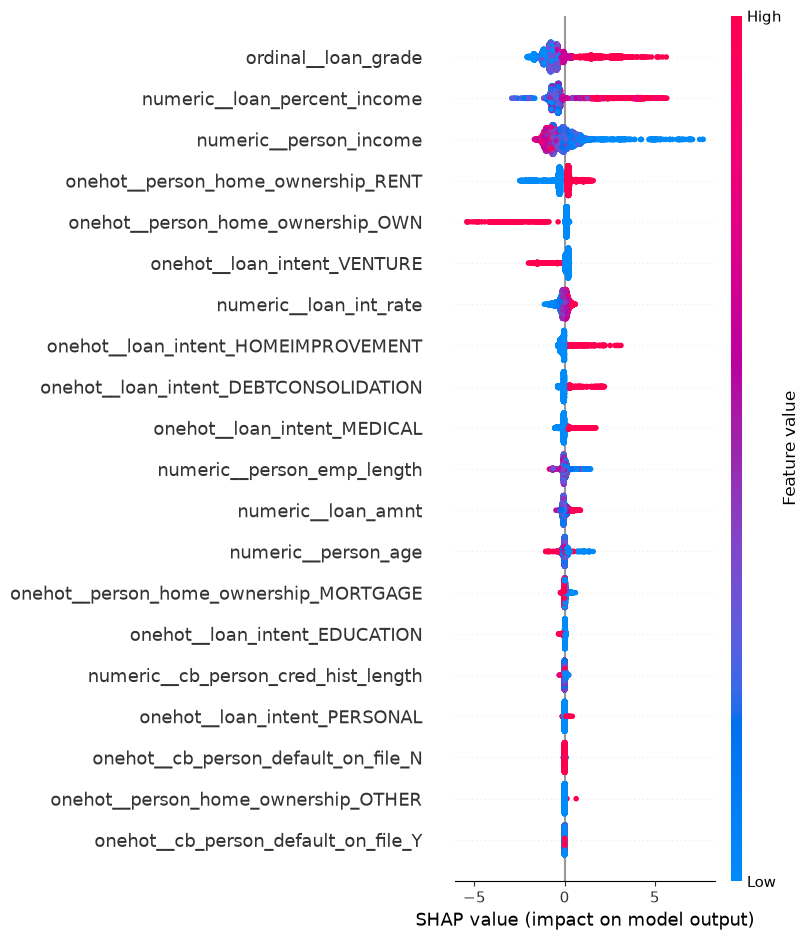

In [222]:
shap.summary_plot(
    shap_values,
    x_test,
    feature_names=feature_names
)

### 7.2 Individual Prediction Explanation

Global SHAP analysis shows which features have the greatest influence on the model overall. However, model interpretability can also be performed at the individual prediction level.

In this section, SHAP is used to explain why XGBoost made a specific prediction for a single loan application.

The explanation shows which features increased or decreased the model's predicted default risk.

In [223]:
# Select one sample from the test set
sample_index = 0

# Get the predicted default probability
sample_probability = xgb_model.predict_proba(x_test)[sample_index, 1]

# Get the actual target value
sample_actual = y_test.iloc[sample_index]

print("Actual label:", sample_actual)
print("Predicted default probability:", sample_probability)

Actual label: 0
Predicted default probability: 0.055884335


In [224]:
# Create a SHAP explanation for the selected sample
sample_explanation = shap.Explanation(
    values=shap_values.values[sample_index],
    base_values=shap_values.base_values[sample_index],
    data=x_test[sample_index],
    feature_names=feature_names
)

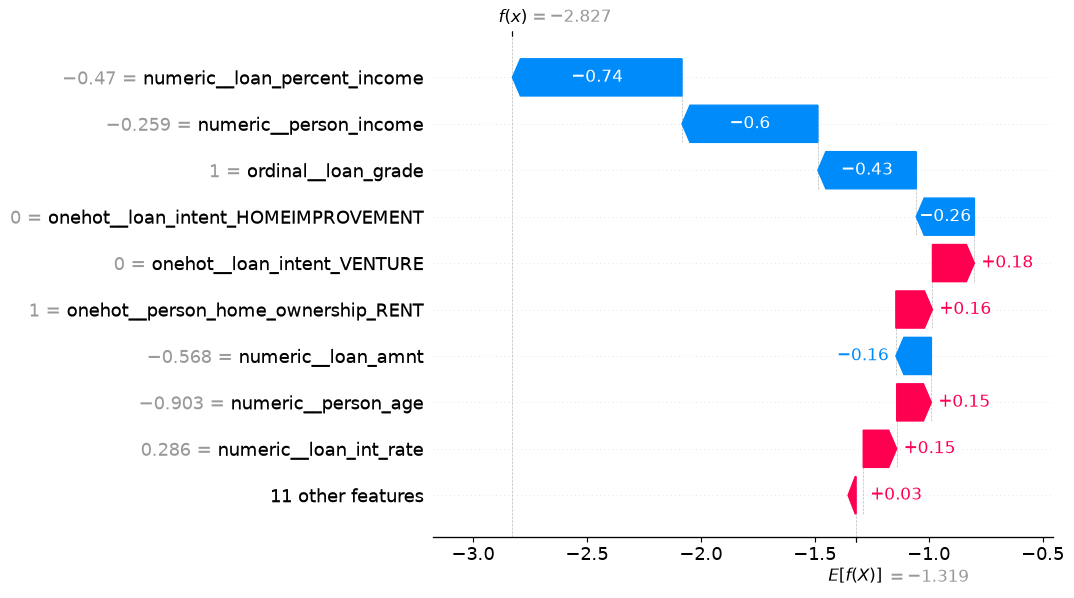

In [225]:
# Visualize the individual prediction explanation
shap.plots.waterfall(
    sample_explanation,
    max_display=10
)

### Interpretation of the Individual Prediction

The SHAP waterfall plot explains how individual features contributed to the XGBoost prediction for a single loan application.

The model output starts from a baseline value of **-1.319** and reaches a final output of **-2.827** after the contributions of the individual features are considered.

The strongest factors reducing the model output were `loan_percent_income` (-0.74), `person_income` (-0.60), and `loan_grade` (-0.43). These features pushed the prediction toward a lower estimated default risk.

In contrast, `loan_intent_VENTURE` (+0.18), `person_home_ownership_RENT` (+0.16), `person_age` (+0.15), and `loan_int_rate` (+0.15) increased the model output and therefore contributed in the opposite direction.

Overall, the prediction demonstrates that the model does not rely on a single feature. Instead, the final prediction results from the combined effect of multiple financial and demographic characteristics.

SHAP therefore provides a local explanation of the model's decision, showing which features pushed the prediction higher or lower for this specific loan application.

## 8. Model Deployment

The trained XGBoost model can be integrated into an application to make predictions on new loan applications.

In this section, the trained preprocessing pipeline and XGBoost model are saved so that they can be reused without retraining the model.

The deployment workflow consists of receiving new input data, applying the same preprocessing steps used during training, generating a prediction with the trained model, and returning the estimated default probability.

In [230]:
 import joblib

# Save the trained XGBoost model
joblib.dump(xgb_model, "../models/xgb_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessor saved successfully.")

Model and preprocessor saved successfully.


In [ ]:
import joblib

# Save the trained XGBoost model
joblib.dump(xgb_model, "../models/xgb_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessor saved successfully.")

### 8.2 Test the Saved Model

The saved model and preprocessing pipeline are loaded again to verify that they can be reused for prediction without retraining.

In [227]:
loaded_model = joblib.load("../models/xgb_model.pkl")
loaded_preprocessor = joblib.load("../models/preprocessor.pkl")

print("Saved model and preprocessor loaded successfully.")

Saved model and preprocessor loaded successfully.


In [229]:
sample = x.iloc[[0]]  # Select one raw sample from the original dataset

sample_transformed = loaded_preprocessor.transform(sample)  # Apply the saved preprocessing

prediction = loaded_model.predict(sample_transformed)[0]  # Predict the class
probability = loaded_model.predict_proba(sample_transformed)[0, 1]  # Get default probability

print("Predicted class:", prediction)
print("Default probability:", probability)

Predicted class: 1
Default probability: 0.9958775


### 8.3 Deployment Result

The saved XGBoost model was successfully loaded and used to generate a prediction on a new sample.

For the tested sample, the model predicted **Default (1)** with a default probability of approximately **99.59%**.

This confirms that the trained model and preprocessing pipeline can be saved, reloaded, and reused for predictions without retraining.

# 9. Conclusion

This project developed an end-to-end machine learning pipeline for credit risk prediction.

The dataset was explored and analyzed to identify its structure, class distribution, missing values, duplicate records, and potential data quality issues. Numerical and categorical features were then processed using an appropriate preprocessing pipeline. Ordinal Encoding was applied to the `loan_grade` feature, while One-Hot Encoding was used for nominal categorical features.

Three classification models were trained and evaluated: Logistic Regression, Random Forest, and XGBoost. XGBoost achieved the strongest overall performance with an accuracy of **93.66%**, precision of **98.28%**, recall of **72.22%**, F1-score of **83.59%**, and ROC-AUC of **94.93%**.

The confusion matrix showed that XGBoost correctly identified **1,027 default cases** while incorrectly classifying **395 default cases as non-default**. This highlights the importance of recall in credit risk applications, where failing to identify a high-risk borrower can have significant consequences.

SHAP analysis was used to interpret the XGBoost model and identify the features that had the greatest influence on its predictions. The most influential features included `loan_grade`, `loan_percent_income`, and `person_income`.

Finally, the trained XGBoost model and preprocessing pipeline were saved and successfully reloaded. A new sample was processed and classified without retraining the model, demonstrating a complete machine learning workflow from raw data to reusable model deployment.

Overall, the project demonstrates how machine learning can be applied to structured financial data while combining predictive performance, model evaluation, interpretability, and deployment considerations.